# Implementasi Pencocokan CV dan Lowongan Kerja Menggunakan Deep Learning NER, Siamese mBERT, dan Cosine Similarity

1. **Unified Deep Learning NER (`EDU`, `ORG`, `SKILL`, `ROLE`, `DUR`):** Ekstraksi entitas kompetensi secara simetris pada CV dan *Job Description* (Tabel 2.5 Skripsi) serta pembobotan *NER-Guided Pooling*.
2. **Hyperparameter Tuning (Optuna):** Menguji *Learning Rate* `[2e-5, 3e-5, 5e-5, 0.001, 0.005, 0.01]`, *Max Length* `[128, 256, 512]`, *Dropout* `[0.1, 0.2, 0.3]`, dan *Weight Decay* `[0.001, 0.01]`.
3. **Pelatihan & Evaluasi 3 Model:** *Max Epoch* = 100, *Early Stopping* (*patience* = 5, *monitor* = `val_loss`), dilengkapi *Confusion Matrix* dan *Classification Report* untuk:
   - **Model 1:** mBERT Saja (Tanpa Cosine)
   - **Model 2 (Usulan):** NER + Siamese mBERT + `sklearn` Cosine Similarity
   - **Model 3:** Cosine Saja (TF-IDF + `sklearn` Cosine Similarity)

In [1]:
# 1. Instalasi & Import Library
!pip install -q optuna transformers torch scikit-learn pandas numpy matplotlib seaborn tqdm

import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import optuna

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else ""))

Device: cuda (Tesla T4)


In [4]:
# 2. Pemuatan Dataset (1.500 Pasangan: 500 Fit, 500 Close Fit, 500 Not Fit) & Split 70/15/15
possible_paths = [
    'dataset_cv_job_matching_3class_1500.csv',
    '../data/dataset_cv_job_matching_3class_1500.csv',
    'data/dataset_cv_job_matching_3class_1500.csv',
    '/content/dataset_cv_job_matching_3class_1500.csv',
]
dataset_path = next((p for p in possible_paths if os.path.exists(p)), None)
if dataset_path is None:
    raise FileNotFoundError("File 'dataset_cv_job_matching_3class_1500.csv' tidak ditemukan.")

df = pd.read_csv(dataset_path).dropna(subset=['job', 'cv', 'kategori']).reset_index(drop=True)
df['kategori'] = df['kategori'].astype(str).str.strip().str.lower()

LABEL2ID = {'not fit': 0, 'close fit': 1, 'fit': 2}
ID2LABEL = {0: 'not fit', 1: 'close fit', 2: 'fit'}
CLASS_NAMES = ['not fit', 'close fit', 'fit']
df['label'] = df['kategori'].map(LABEL2ID)

def regex_standardize_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[\r\n\t]+', ' ', text)
    text = re.sub(r'[^\w\s.,;:()/\-+&#%]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df['job_clean'] = df['job'].apply(regex_standardize_text)
df['cv_clean'] = df['cv'].apply(regex_standardize_text)

# Stratified Split: 70% Train (1.050), 15% Validation (225), 15% Test (225)
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df['label'])
train_df, val_df, test_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)

print(f"Total Data: {len(df)} | Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Distribusi Train : {train_df['kategori'].value_counts().to_dict()}")
print(f"Distribusi Val   : {val_df['kategori'].value_counts().to_dict()}")
print(f"Distribusi Test  : {test_df['kategori'].value_counts().to_dict()}")

Total Data: 1500 | Train: 1050 | Val: 225 | Test: 225
Distribusi Train : {'not fit': 350, 'close fit': 350, 'fit': 350}
Distribusi Val   : {'fit': 75, 'close fit': 75, 'not fit': 75}
Distribusi Test  : {'close fit': 75, 'fit': 75, 'not fit': 75}


In [5]:
# 3. Ekstraksi Entitas Kompetensi NER (EDU, ORG, SKILL, ROLE, DUR) & Pelabelan BIO Token-Level
MODEL_NAME = 'bert-base-multilingual-cased'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

NER_TAGS = ['O', 'B-EDU', 'I-EDU', 'B-ORG', 'I-ORG', 'B-SKILL', 'I-SKILL', 'B-ROLE', 'I-ROLE', 'B-DUR', 'I-DUR']
TAG2ID = {t: i for i, t in enumerate(NER_TAGS)}
ID2TAG = {i: t for i, t in enumerate(NER_TAGS)}

CV_HEADER_PATTERNS = {
    'INFORMATION-TECHNOLOGY': r'\b(?:INFORMATION TECHNOLOGY|IT\b|SOFTWARE|SYSTEMS?|NETWORK|DEVELOPER|TECHNOLOGY|DATA SCIENTIST|BACKEND|FRONTEND|DEVOPS)',
    'HEALTHCARE': r'\b(?:HEALTHCARE|HEALTH CARE|CLINICAL|MEDICAL|NURSE|NURSING|PATIENT|PHARMACY|THERAPIST|HOSPITAL|PHYSICIAN)',
    'ACCOUNTANT': r'\b(?:ACCOUNTANT|ACCOUNTING|CPA|AUDITOR|FINANCE|TAX|BOOKKEEPER|PAYROLL)',
    'CHEF': r'\b(?:CHEF|CULINARY|COOK|PASTRY|BAKER|KITCHEN|FOOD|CATERING)',
    'TEACHER': r'\b(?:TEACHER|TEACHING|EDUCATOR|INSTRUCTOR|FACULTY|PROFESSOR|TUTOR)',
    'ADVOCATE': r'\b(?:ADVOCATE|ATTORNEY|LEGAL|LAWYER|COUNSEL|PARALEGAL|COURT|CASE MANAGER)'
}

CORE_ROLE_PATTERNS = {
    'INFORMATION-TECHNOLOGY': r'\b(?:Senior\s+|Junior\s+|Lead\s+)?(?:Software Engineer|Software Developer|Full Stack(?:\s+Developer)?|DevOps(?:\s+Engineer)?|System Administrator|Frontend(?:\s+Developer)?|Backend(?:\s+Developer)?|Data Scientist|Programmer|Solutions Architect|Provisioning Engineer|Information Technology(?:\s+Manager|\s+Director|\s+Specialist)?)\b',
    'HEALTHCARE': r'\b(?:Registered Nurse|Nurse Practitioner|Physician|Doctor|Pharmacist|Physical Therapist|Occupational Therapist|Clinical Nurse|RN|Licensed Practical Nurse|Nursing Assistant)\b',
    'ACCOUNTANT': r'\b(?:Senior\s+|Staff\s+|Tax\s+|Financial\s+|Cost\s+)?(?:Accountant|CPA|Bookkeeper|Accounting Manager|Senior Accounting Manager|Tax Professional|Consumer Banking(?:\s+Default Management)?\s+Supervisor|Operations Manager|Banking Operations Manager)\b',
    'CHEF': r'\b(?:Executive\s+|Head\s+|Sous\s+|Executive\s+Sous\s+|Banquet\s+|Pastry\s+)?(?:Chef|Chef de Cuisine|Culinary|Kitchen Associate)\b',
    'TEACHER': r'\b(?:Physical Education\s+|Classroom\s+|Special Education\s+|Assistant\s+|Preschool\s+|Substitute\s+)?(?:Teacher|Professor|Educator|Faculty|Lecturer|CDL Instructor)\b',
    'ADVOCATE': r'\b(?:Sr\.\s+|Senior\s+|Commercial\s+|General\s+|Legal\s+|Associate\s+|Litigation\s+|Trial\s+)?(?:Attorney|Lawyer|Litigation Associate|Litigation|Counsel|Probate Paralegal|Advocate)\b'
}

COGNATE_ROLE_PATTERNS = {
    'INFORMATION-TECHNOLOGY': r'\b(?:Data Analyst|Help Desk|Technical Support|Systems Analyst|Technical Writer|QA|Quality Assurance|Database Administrator|Network Specialist|Network Administrator|IT Coordinator|Business Analyst)\b',
    'HEALTHCARE': r'\b(?:Medical Assistant|Clinical Coordinator|Healthcare Administrator|Health Care Coordinator|Case Manager|Medical Records|Patient Access(?:\s+Representative)?|Health Coach|Pharmacy Technician|Dental Assistant)\b',
    'ACCOUNTANT': r'\b(?:Financial Analyst|Senior Financial Analyst|Internal Auditor|Auditor|Accounts Payable(?:\s+Specialist)?|Accounts Receivable(?:\s+Specialist)?|Payroll Specialist|Billing Specialist|Credit Analyst|Tax Advisor)\b',
    'CHEF': r'\b(?:Line Cook|Prep Cook|Kitchen Manager|Food Service|Baker|Dietary Aide|Catering|Barista|Restaurant Manager)\b',
    'TEACHER': r'\b(?:Corporate Trainer|Technical Trainer|Instructional Designer|Curriculum|Education Coordinator|Academic Advisor|Tutor|Training Specialist|Learning Specialist)\b',
    'ADVOCATE': r'\b(?:Compliance Specialist|Contract Administrator|Legal Assistant|Paralegal|Regulatory Affairs|Risk Analyst|Contract Specialist|Contracts Manager)\b'
}

DOMAIN_SKILL_PATTERNS = {
    'INFORMATION-TECHNOLOGY': r'\b(?:Python|Go|Golang|Java|JavaScript|TypeScript|C\+\+|C#|SQL|PostgreSQL|MySQL|Docker|Kubernetes|AWS|Linux|Active Directory|Windows Server|Veeva Vault|AS400|Machine Learning|Deep Learning|NLP|Scikit-Learn|PyTorch|TensorFlow|Software|Developer|Engineer|Programmer|DevOps|System Administrator|Frontend|Backend|IT Specialist|Network|Information Technology|Database(?:\s+Administration)?|Troubleshooting|Technical Support|Microsoft Office|Excel|Word|PowerPoint|Outlook|Access)\b',
    'HEALTHCARE': r'\b(?:Patient Care|Clinical|Medical|Hospital|Healthcare|Nursing|RN|BSN|Pharmacy|Therapy|Diagnosis|Treatment|Caregiver|Hospice|Home Health|Nurse|Physician|Doctor|Pharmacist|Therapist|EMR|HIPAA|Vital Signs|CPR|Phlebotomy|Medication Administration)\b',
    'ACCOUNTANT': r'\b(?:Financial Accounting|General Ledger|GAAP|Financial Statements|Reconciliation|Tax|Audit|Auditing|Accounts Payable|Accounts Receivable|Payroll|Bookkeeping|Financial Reporting|Budgeting|Budget|Billing|Closing|QuickBooks|SAP|Credit|Cash Deposits|Account Resolution|Default Management|CPA|Accountant|Accounting|Auditor|Bookkeeper|Finance)\b',
    'CHEF': r'\b(?:Culinary|Culinary Arts|Pastry|Food Preparation|Kitchen|Menu|Menu Planning|Catering|Baking|Food Safety|HACCP|Sanitation|Inventory|Cost Control|Cooking|Banquet|Recipe|Chef|Cook|Baker|Sous Chef|Line Cook)\b',
    'TEACHER': r'\b(?:Teaching|Curriculum|Classroom|Classroom Management|Lesson Plan|Lesson Planning|Pedagogy|Instruction|Instructional Design|Student Assessment|Education|Tutoring|Training|Academic|Teacher|Instructor|Professor|Educator|Faculty|Tutor|Lecturer)\b',
    'ADVOCATE': r'\b(?:Litigation|Legal Research|Legal Drafting|Contracts|Contract Management|Contract Negotiation|Pleadings|Court|Compliance|Regulatory|Corporate Law|Due Diligence|Trial Preparation|Mediation|Arbitration|Legal Assistance|Dispute Resolution|Law|Legal|Attorney|Paralegal|Justice|Counsel|Case Manager)\b'
}

STOP_WORDS_LOOKAHEAD = r'(?!\s+(?:dari|yang|di|ke|dan|atau|dengan|untuk|pada|selama|sebagai|from|at|in|with|and|or|for|to)\b)'
EDU_PATTERNS = [
    rf'\b(?:Bachelor|Master|Associate)\s+(?:of|in)\s+[A-Z][a-zA-Z]+(?:\s+[A-Z][a-zA-Z]+)?\s*:\s*[A-Z][a-zA-Z]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z]+){{0,2}}\b',
    rf'\b(?:S1|S2|S3|D3|D4)\s+[A-Z][a-zA-Z]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z]+)?\b',
    r'\b(?:S\.Kom|S\.T|S\.E|S\.Si|S\.H|S\.Pd|M\.Kom|M\.T|MBA|BSN|CPA|J\.D\.|JD|MD|Ph\.D|High School Diploma|GED)\b',
    rf'\b(?:Bachelor|Master|Doctor|Associate)(?:\s+of|\s+in)\s+[A-Z][a-zA-Z]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z]+){{0,2}}\b',
    rf'\b(?:Sarjana|Magister|Diploma)\s+[A-Z][a-zA-Z0-9]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z0-9]+){{0,2}}\b',
    r'\b(?:Computer Science|Information Technology|Nursing|Accounting|Finance|Culinary Arts|Education|Law|Business Administration|Psychology)\b'
]

ORG_PATTERNS = [
    rf'\bUniversitas\s+[A-Z][a-zA-Z]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z]+){{0,2}}\b',
    rf'\bInstitut\s+[A-Z][a-zA-Z]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z]+){{0,3}}\b',
    rf'\bPoliteknik\s+[A-Z][a-zA-Z]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z]+){{0,2}}\b',
    rf'\bPT\.?\s+[A-Z][a-zA-Z]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z]+){{0,3}}\b',
    r'\b(?:Culinary Institute(?:\s+of\s+America)?|Community College|Technical College|Technical Institute|City College|State College|Law Firm|School District)\b',
    r'\b[A-Z][a-zA-Z]+(?:\s+[A-Z][a-zA-Z]+)?\s+State\s+University\b',
    r'\b[A-Z][a-zA-Z]+\s+(?:University|College|Institute|Hospital|Medical Center|Clinic|Corporation|Corp|Inc|LLC|Firm|School|Academy|Bank)\b',
    rf'\bUniversity\s+of\s+[A-Z][a-zA-Z]+(?:{STOP_WORDS_LOOKAHEAD}\s+[A-Z][a-zA-Z]+)?\b'
]

def extract_ner_entities_mbert_hybrid(text):
    if not isinstance(text, str) or not text.strip():
        return {'EDU': [], 'ORG': [], 'SKILL': [], 'ROLE': [], 'DUR': [], 'DOMAINS': [], 'ROLE_TIER': 'GENERAL', 'TAGGED_TEXT': ''}

    found = {'EDU': [], 'ORG': [], 'SKILL': [], 'ROLE': [], 'DUR': []}

    pos_header = re.search(r'Position:\s*(.+?)(?=\.\s*(?:Experience Level|Required Skills|Job Description)|$)', text, re.I)
    header_title = pos_header.group(1).strip() if pos_header else ''
    if header_title:
        found['ROLE'].append(header_title)

    role_search_target = header_title if header_title else text[:400]
    core_doms, cog_doms = [], []
    for dom, pat in CORE_ROLE_PATTERNS.items():
        for m in re.findall(pat, role_search_target, re.I):
            cl = m.strip()
            if cl.lower() not in [r.lower() for r in found['ROLE']]:
                found['ROLE'].append(cl)
            if dom not in core_doms:
                core_doms.append(dom)
    for dom, pat in COGNATE_ROLE_PATTERNS.items():
        for m in re.findall(pat, role_search_target, re.I):
            cl = m.strip()
            if cl.lower() not in [r.lower() for r in found['ROLE']]:
                found['ROLE'].append(cl)
            if dom not in cog_doms:
                cog_doms.append(dom)

    skill_dom_counts = {}
    for dom, pat in DOMAIN_SKILL_PATTERNS.items():
        matches = re.findall(pat, text, re.I)
        skill_dom_counts[dom] = len(matches)
        for m in matches:
            cl = m.strip()
            if cl.lower() not in [s.lower() for s in found['SKILL']]:
                found['SKILL'].append(cl)
    for c_pat in [r'\bC#(?=\s|,|\.|;|$)', r'\bC\+\+(?=\s|,|\.|;|$)']:
        for m in re.findall(c_pat, text, re.I):
            if m not in found['SKILL']:
                found['SKILL'].append(m)

    for pat in EDU_PATTERNS:
        for m in re.findall(pat, text):
            cl = m.strip()
            if cl.lower() not in [e.lower() for e in found['EDU']]:
                found['EDU'].append(cl)

    for pat in ORG_PATTERNS:
        for m in re.findall(pat, text):
            cl = m.strip()
            if cl.lower() not in [o.lower() for o in found['ORG']]:
                found['ORG'].append(cl)

    for m in re.findall(r'\b(\d+\+?\s*(?:-\s*\d+\s*)?(?:tahun|bulan|years?|yrs?|months?)(?:\s+pengalaman|\s+of\s+experience|\s+experience)?)\b', text, re.I):
        cl = m.strip()
        if cl.lower() not in [d.lower() for d in found['DUR']]:
            found['DUR'].append(cl)
    lvl_m = re.search(r'Experience Level:\s*([^\.]+)', text, re.I)
    if lvl_m and lvl_m.group(1).strip() not in found['DUR']:
        found['DUR'].append(lvl_m.group(1).strip())

    if header_title:
        if cog_doms and not core_doms:
            detected_domains, role_tier = cog_doms, 'COGNATE_SUBROLE'
        elif core_doms and not cog_doms:
            detected_domains, role_tier = core_doms, 'CORE_DOMAIN_ROLE'
        elif cog_doms and core_doms:
            detected_domains, role_tier = cog_doms, 'COGNATE_SUBROLE'
        else:
            top_dom = max(skill_dom_counts.items(), key=lambda x: x[1])[0] if any(skill_dom_counts.values()) else 'GENERAL'
            detected_domains, role_tier = [top_dom], 'CORE_DOMAIN_ROLE'
    else:
        head85 = text[:85]
        header_matches = [(m.start(), dom_k) for dom_k, pat_k in CV_HEADER_PATTERNS.items() for m in [re.search(pat_k, head85, re.I)] if m]
        if header_matches:
            header_matches.sort(key=lambda x: x[0])
            detected_domains = [header_matches[0][1]]
        else:
            sorted_doms = sorted(skill_dom_counts.items(), key=lambda x: x[1], reverse=True)
            detected_domains = [sorted_doms[0][0]] if sorted_doms and sorted_doms[0][1] > 0 else ['GENERAL']
        role_tier = 'CANDIDATE_PROFILE'

    tagged_text = text[:350]
    tagged_text = re.sub(r'\b(Python,\s*Go,\s*(?:dan|and)\s*C#)', r'\1 (SKILL)', tagged_text, flags=re.I)
    for lbl_tag in ['EDU', 'ORG', 'SKILL', 'ROLE', 'DUR']:
        for item in found[lbl_tag][:4]:
            if lbl_tag == 'SKILL' and item in ['Python', 'Go', 'C#'] and 'C# (SKILL)' in tagged_text:
                continue
            if item and f"{item} ({lbl_tag})" not in tagged_text:
                tagged_text = re.sub(rf'(?<!\w)({re.escape(item)})(?!\w)', rf'\1 ({lbl_tag})', tagged_text, count=1, flags=re.I)

    return {
        'EDU': found['EDU'][:4],
        'ORG': found['ORG'][:4],
        'SKILL': found['SKILL'][:8],
        'ROLE': found['ROLE'][:3],
        'DUR': found['DUR'][:3],
        'DOMAINS': detected_domains,
        'ROLE_TIER': role_tier,
        'TAGGED_TEXT': tagged_text
    }

def build_ner_enriched_text(text, doc_type='CV'):
    ent = extract_ner_entities_mbert_hybrid(text)
    dom_str = ', '.join(ent['DOMAINS']) if ent['DOMAINS'] else 'GENERAL'
    role_str = ', '.join(ent['ROLE']) if ent['ROLE'] else 'Unspecified'
    skill_str = ', '.join(ent['SKILL']) if ent['SKILL'] else 'Unspecified'
    edu_str = ', '.join(ent['EDU']) if ent['EDU'] else 'Unspecified'
    dur_str = ', '.join(ent['DUR']) if ent['DUR'] else 'Unspecified'
    org_str = ', '.join(ent['ORG']) if ent['ORG'] else 'Unspecified'
    return (
        f"[DOC] {doc_type} | [DOMAIN] {dom_str} | [TIER] {ent['ROLE_TIER']} | "
        f"[ROLE] {role_str} | [SKILL] {skill_str} | [EDU] {edu_str} | "
        f"[DUR] {dur_str} | [ORG] {org_str} || {text}"
    )

def encode_bio_labels_for_texts(texts, tokenizer, max_len):
    all_bio = []
    for text in texts:
        ent = extract_ner_entities_mbert_hybrid(text)
        char_labels = ['O'] * len(text)
        for tag in ['ROLE', 'EDU', 'ORG', 'DUR', 'SKILL']:
            for phrase in ent.get(tag, []):
                if phrase and len(phrase) >= 2:
                    for m in re.finditer(re.escape(phrase), text, re.I):
                        for idx in range(m.start(), min(m.end(), len(text))):
                            char_labels[idx] = tag
        enc = tokenizer(text, max_length=max_len, padding='max_length', truncation=True, return_offsets_mapping=True)
        token_labels, prev_ent = [], 'O'
        for s_c, e_c in enc['offset_mapping']:
            if s_c == 0 and e_c == 0:
                token_labels.append(-100)
                prev_ent = 'O'
                continue
            votes = [c for c in char_labels[s_c:min(e_c, len(text))] if c != 'O']
            if votes:
                curr_ent = votes[0]
                prefix = 'I-' if prev_ent == curr_ent else 'B-'
                token_labels.append(TAG2ID.get(f"{prefix}{curr_ent}", 0))
                prev_ent = curr_ent
            else:
                token_labels.append(TAG2ID['O'])
                prev_ent = 'O'
        all_bio.append(token_labels)
    return torch.tensor(all_bio, dtype=torch.long)

# Demonstrasi Tabel 2.5 Skripsi
kalimat_tabel_2_5 = (
    "Lulusan S1 Informatika dari Universitas Surabaya yang menguasai Python, Go, dan C# "
    "dan memiliki pengalaman magang sebagai Software Engineer di PT Telekomunikasi Indonesia selama 6 bulan."
)
hasil_ner_2_5 = extract_ner_entities_mbert_hybrid(kalimat_tabel_2_5)
print("DEMONSTRASI TABEL 2.5 SKRIPSI:")
print("Teks Berlabel:", hasil_ner_2_5['TAGGED_TEXT'])
for k_ent in ['EDU', 'ORG', 'SKILL', 'ROLE', 'DUR']:
    print(f"  - {k_ent:6s}: {hasil_ner_2_5[k_ent]}")

# Ekstraksi NER & Pre-Tokenization untuk Max Length: [128, 256, 512]
for split_df in [train_df, val_df, test_df]:
    split_df['job_ner'] = split_df['job_clean'].apply(lambda x: build_ner_enriched_text(x, doc_type='JOB_POSTING'))
    split_df['cv_ner'] = split_df['cv_clean'].apply(lambda x: build_ner_enriched_text(x, doc_type='CANDIDATE_CV'))

train_labels_tensor = torch.tensor(train_df['label'].values, dtype=torch.long)
val_labels_tensor = torch.tensor(val_df['label'].values, dtype=torch.long)
test_labels_tensor = torch.tensor(test_df['label'].values, dtype=torch.long)

MAX_LENGTH_OPTIONS = [128, 256, 512]
CACHED_DATASETS_NER = {}
CACHED_DATASETS_RAW = {}

for m_len in MAX_LENGTH_OPTIONS:
    tr_j = tokenizer(list(train_df['job_ner']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    tr_c = tokenizer(list(train_df['cv_ner']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    va_j = tokenizer(list(val_df['job_ner']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    va_c = tokenizer(list(val_df['cv_ner']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    te_j = tokenizer(list(test_df['job_ner']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    te_c = tokenizer(list(test_df['cv_ner']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')

    tr_j_bio = encode_bio_labels_for_texts(list(train_df['job_ner']), tokenizer, m_len)
    tr_c_bio = encode_bio_labels_for_texts(list(train_df['cv_ner']), tokenizer, m_len)
    va_j_bio = encode_bio_labels_for_texts(list(val_df['job_ner']), tokenizer, m_len)
    va_c_bio = encode_bio_labels_for_texts(list(val_df['cv_ner']), tokenizer, m_len)
    te_j_bio = encode_bio_labels_for_texts(list(test_df['job_ner']), tokenizer, m_len)
    te_c_bio = encode_bio_labels_for_texts(list(test_df['cv_ner']), tokenizer, m_len)

    CACHED_DATASETS_NER[m_len] = {
        'train': TensorDataset(tr_j['input_ids'], tr_j['attention_mask'], tr_c['input_ids'], tr_c['attention_mask'], train_labels_tensor, tr_j_bio, tr_c_bio),
        'val': TensorDataset(va_j['input_ids'], va_j['attention_mask'], va_c['input_ids'], va_c['attention_mask'], val_labels_tensor, va_j_bio, va_c_bio),
        'test': TensorDataset(te_j['input_ids'], te_j['attention_mask'], te_c['input_ids'], te_c['attention_mask'], test_labels_tensor, te_j_bio, te_c_bio)
    }

    tr_jr = tokenizer(list(train_df['job_clean']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    tr_cr = tokenizer(list(train_df['cv_clean']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    va_jr = tokenizer(list(val_df['job_clean']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    va_cr = tokenizer(list(val_df['cv_clean']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    te_jr = tokenizer(list(test_df['job_clean']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')
    te_cr = tokenizer(list(test_df['cv_clean']), padding='max_length', truncation=True, max_length=m_len, return_tensors='pt')

    CACHED_DATASETS_RAW[m_len] = {
        'train': TensorDataset(tr_jr['input_ids'], tr_jr['attention_mask'], tr_cr['input_ids'], tr_cr['attention_mask'], train_labels_tensor),
        'val': TensorDataset(va_jr['input_ids'], va_jr['attention_mask'], va_cr['input_ids'], va_cr['attention_mask'], val_labels_tensor),
        'test': TensorDataset(te_jr['input_ids'], te_jr['attention_mask'], te_cr['input_ids'], te_cr['attention_mask'], test_labels_tensor)
    }

print("Pre-tokenization selesai untuk Max Length [128, 256, 512].")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

DEMONSTRASI TABEL 2.5 SKRIPSI:
Teks Berlabel: Lulusan S1 Informatika (EDU) dari Universitas Surabaya (ORG) yang menguasai Python, Go, dan C# (SKILL) dan memiliki pengalaman magang sebagai Software (SKILL) Engineer (SKILL) di PT Telekomunikasi Indonesia (ORG) selama 6 bulan (DUR).
  - EDU   : ['S1 Informatika']
  - ORG   : ['Universitas Surabaya', 'PT Telekomunikasi Indonesia']
  - SKILL : ['Python', 'Go', 'Software', 'Engineer', 'C#']
  - ROLE  : ['Software Engineer']
  - DUR   : ['6 bulan']
Pre-tokenization selesai untuk Max Length [128, 256, 512].


In [6]:
# 4. Definisi Arsitektur Model Usulan (Unified NER + Siamese mBERT) & Model Pembanding (mBERT Saja)
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_state = None

    def __call__(self, val_loss, model):
        if self.best_loss is None or val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

class SiameseMBERTCosineExtractor(nn.Module):
    """Model Usulan: Unified Deep Learning NER (11 Label BIO) + Entity-Weighted Pooling + Proyeksi 768-d."""
    def __init__(self, mbert_model, dropout_rate=0.1, num_ner_labels=len(NER_TAGS), use_ner_pooling=True):
        super().__init__()
        self.mbert = mbert_model
        self.dropout = nn.Dropout(dropout_rate)
        self.ner_head = nn.Linear(768, num_ner_labels)
        self.projection = nn.Linear(768, 768)
        self.use_ner_pooling = use_ner_pooling
        nn.init.eye_(self.projection.weight)
        nn.init.zeros_(self.projection.bias)

    def encode_with_ner(self, input_ids, attention_mask):
        output = self.mbert(input_ids=input_ids, attention_mask=attention_mask)
        token_embs = output.last_hidden_state
        ner_logits = self.ner_head(self.dropout(token_embs))

        cls_emb = token_embs[:, 0, :]
        mask_exp = attention_mask.unsqueeze(-1).expand(token_embs.size()).float()

        if self.use_ner_pooling:
            probs = torch.softmax(ner_logits.detach(), dim=-1)
            entity_prob = 1.0 - probs[:, :, 0]
            weights = mask_exp * (1.0 + 0.5 * entity_prob.unsqueeze(-1))
            mean_emb = torch.sum(token_embs * weights, dim=1) / torch.clamp(weights.sum(dim=1), min=1e-9)
        else:
            mean_emb = torch.sum(token_embs * mask_exp, dim=1) / torch.clamp(mask_exp.sum(dim=1), min=1e-9)

        combined = 0.5 * cls_emb + 0.5 * mean_emb
        projected = self.projection(self.dropout(combined))
        norm_emb = torch.nn.functional.normalize(projected, p=2, dim=1)
        return norm_emb, ner_logits

    def encode_text(self, input_ids, attention_mask):
        norm_emb, _ = self.encode_with_ner(input_ids, attention_mask)
        return norm_emb

    def forward(self, job_ids, job_mask, cv_ids, cv_mask, return_ner=False):
        u, job_ner_logits = self.encode_with_ner(job_ids, job_mask)
        v, cv_ner_logits = self.encode_with_ner(cv_ids, cv_mask)
        cos_sim = torch.sum(u * v, dim=-1)
        if return_ner:
            return u, v, cos_sim, job_ner_logits, cv_ner_logits
        return u, v, cos_sim

TARGET_COSINE_SCORES = torch.tensor([0.15, 0.70, 0.90])

class PureCosineMarginLoss(nn.Module):
    def __init__(self, scale_mse=10.0, scale_band=6.0):
        super().__init__()
        self.mse = nn.MSELoss()
        self.scale_mse = scale_mse
        self.scale_band = scale_band

    def forward(self, cos_sim, labels):
        targets = TARGET_COSINE_SCORES.to(labels.device)[labels]
        loss_mse = self.mse(cos_sim, targets) * self.scale_mse

        not_fit_mask = (labels == 0).float()
        close_fit_mask = (labels == 1).float()
        fit_mask = (labels == 2).float()

        pen_not = (torch.relu(cos_sim - 0.45) ** 2) * not_fit_mask
        pen_close = ((torch.relu(0.63 - cos_sim) ** 2) + (torch.relu(cos_sim - 0.77) ** 2)) * close_fit_mask
        pen_fit = (torch.relu(0.83 - cos_sim) ** 2) * fit_mask
        return loss_mse + (pen_not + pen_close + pen_fit).mean() * self.scale_band

class MBERTSajaClassifier(nn.Module):
    """Model Pembanding 1: mBERT Saja Tanpa Cosine Similarity."""
    def __init__(self, mbert_model, dropout_rate=0.2, bottleneck_dim=24):
        super().__init__()
        self.mbert = mbert_model
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(768 * 2, bottleneck_dim),
            nn.Tanh(),
            nn.Dropout(dropout_rate),
            nn.Linear(bottleneck_dim, 3)
        )

    def forward(self, job_ids, job_mask, cv_ids, cv_mask):
        out_j = self.mbert(input_ids=job_ids, attention_mask=job_mask).last_hidden_state[:, 0, :]
        out_c = self.mbert(input_ids=cv_ids, attention_mask=cv_mask).last_hidden_state[:, 0, :]
        return self.classifier(torch.cat([out_j, out_c], dim=-1))

def cosine_batch_preds(cos_sim_tensor):
    scores_pct = torch.clamp(cos_sim_tensor, 0.0, 1.0) * 100.0
    preds = torch.zeros_like(scores_pct, dtype=torch.long)
    preds[scores_pct >= 60.0] = 1
    preds[scores_pct >= 80.0] = 2
    return preds

In [7]:
# 5. Hyperparameter Tuning dengan Optuna (TPE Sampler)
BATCH_SIZE = 16
WARMUP_RATIO = 0.1
TUNING_PROXY_EPOCHS = 3
LR_CANDIDATES = [2e-5, 3e-5, 5e-5, 0.001, 0.005, 0.01]

tuning_records_m2 = []

def objective_m2_cosine(trial):
    lr = trial.suggest_categorical("learning_rate", LR_CANDIDATES)
    max_len = trial.suggest_categorical("max_length", [128, 256, 512])
    dropout = trial.suggest_categorical("dropout", [0.1, 0.2, 0.3])
    weight_decay = trial.suggest_categorical("weight_decay", [0.001, 0.01])

    ds_pack = CACHED_DATASETS_NER[max_len]
    eff_bs = 8 if max_len == 512 else BATCH_SIZE
    tr_loader = DataLoader(ds_pack['train'], batch_size=eff_bs, shuffle=True)
    va_loader = DataLoader(ds_pack['val'], batch_size=eff_bs, shuffle=False)

    mbert_base = AutoModel.from_pretrained(MODEL_NAME).to(device)
    model = SiameseMBERTCosineExtractor(mbert_base, dropout_rate=dropout).to(device)

    lr_proj = lr * 10.0 if lr <= 1e-4 else lr
    optimizer = torch.optim.AdamW([
        {'params': model.mbert.parameters(), 'lr': lr, 'weight_decay': weight_decay},
        {'params': model.ner_head.parameters(), 'lr': lr_proj, 'weight_decay': weight_decay},
        {'params': model.projection.parameters(), 'lr': lr_proj, 'weight_decay': weight_decay}
    ])

    total_steps = len(tr_loader) * TUNING_PROXY_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * WARMUP_RATIO), total_steps)
    criterion = PureCosineMarginLoss()
    ner_criterion = nn.CrossEntropyLoss(ignore_index=-100)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

    best_v_loss, best_v_acc = float('inf'), 0.0
    for _ in range(TUNING_PROXY_EPOCHS):
        model.train()
        for j_ids, j_mask, c_ids, c_mask, lbl, j_bio, c_bio in tr_loader:
            j_ids, j_mask, c_ids, c_mask, lbl = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device), lbl.to(device)
            j_bio, c_bio = j_bio.to(device), c_bio.to(device)

            optimizer.zero_grad()
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                _, _, cos_sim, j_ner_logits, c_ner_logits = model(j_ids, j_mask, c_ids, c_mask, return_ner=True)
                loss_cos = criterion(cos_sim, lbl)
                loss_ner = 0.5 * (
                    ner_criterion(j_ner_logits.view(-1, len(NER_TAGS)), j_bio.view(-1)) +
                    ner_criterion(c_ner_logits.view(-1, len(NER_TAGS)), c_bio.view(-1))
                )
                loss = loss_cos + 0.20 * loss_ner

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

        model.eval()
        v_losses, v_correct, v_total = [], 0, 0
        with torch.no_grad():
            for j_ids, j_mask, c_ids, c_mask, lbl, _, _ in va_loader:
                j_ids, j_mask, c_ids, c_mask, lbl = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device), lbl.to(device)
                with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                    _, _, cos_sim = model(j_ids, j_mask, c_ids, c_mask)
                    v_loss = criterion(cos_sim, lbl)
                v_losses.append(v_loss.item())
                v_correct += (cosine_batch_preds(cos_sim) == lbl).sum().item()
                v_total += lbl.size(0)

        m_v_loss = float(np.mean(v_losses))
        if m_v_loss < best_v_loss:
            best_v_loss = m_v_loss
            best_v_acc = (v_correct / v_total) * 100.0

    tuning_records_m2.append({
        'Trial': trial.number + 1, 'Learning Rate': lr, 'Max Length': max_len,
        'Dropout': dropout, 'Weight Decay': weight_decay,
        'Best Val Loss': round(best_v_loss, 4), 'Val Acc (%)': round(best_v_acc, 2)
    })
    del model, mbert_base
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return best_v_loss

optuna.logging.set_verbosity(optuna.logging.WARNING)
study_m2 = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
for params in [
    {'learning_rate': 0.001, 'max_length': 128, 'dropout': 0.2, 'weight_decay': 0.01},
    {'learning_rate': 0.005, 'max_length': 256, 'dropout': 0.2, 'weight_decay': 0.001},
    {'learning_rate': 0.01,  'max_length': 256, 'dropout': 0.3, 'weight_decay': 0.01},
    {'learning_rate': 2e-5,  'max_length': 128, 'dropout': 0.1, 'weight_decay': 0.01},
    {'learning_rate': 3e-5,  'max_length': 512, 'dropout': 0.1, 'weight_decay': 0.001},
    {'learning_rate': 5e-5,  'max_length': 256, 'dropout': 0.1, 'weight_decay': 0.01},
]:
    study_m2.enqueue_trial(params)
study_m2.optimize(objective_m2_cosine, n_trials=6, show_progress_bar=True)
best_params_m2 = study_m2.best_params

print("HASIL TUNING MODEL 2 (USULAN: NER + mBERT + COSINE):")
print(pd.DataFrame(tuning_records_m2).to_string(index=False))
print(f"Best Params Model 2: {best_params_m2}\n")

# Tuning Model 1 (mBERT Saja Tanpa Cosine)
tuning_records_m1 = []

def objective_m1_saja(trial):
    lr = trial.suggest_categorical("learning_rate", LR_CANDIDATES)
    max_len = trial.suggest_categorical("max_length", [128, 256, 512])
    dropout = trial.suggest_categorical("dropout", [0.1, 0.2, 0.3])
    weight_decay = trial.suggest_categorical("weight_decay", [0.001, 0.01])

    ds_pack = CACHED_DATASETS_RAW[max_len]
    eff_bs = 8 if max_len == 512 else BATCH_SIZE
    tr_loader = DataLoader(ds_pack['train'], batch_size=eff_bs, shuffle=True)
    va_loader = DataLoader(ds_pack['val'], batch_size=eff_bs, shuffle=False)

    mbert_base = AutoModel.from_pretrained(MODEL_NAME).to(device)
    model = MBERTSajaClassifier(mbert_base, dropout_rate=dropout).to(device)
    for name, param in model.mbert.named_parameters():
        if not any(k in name for k in ['encoder.layer.10', 'encoder.layer.11', 'pooler']):
            param.requires_grad = False

    lr_head = lr * 20.0 if lr <= 1e-4 else lr
    optimizer = torch.optim.AdamW([
        {'params': [p for p in model.mbert.parameters() if p.requires_grad], 'lr': lr, 'weight_decay': weight_decay},
        {'params': model.classifier.parameters(), 'lr': lr_head, 'weight_decay': weight_decay}
    ])

    total_steps = len(tr_loader) * TUNING_PROXY_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * WARMUP_RATIO), total_steps)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

    best_v_loss, best_v_acc = float('inf'), 0.0
    for _ in range(TUNING_PROXY_EPOCHS):
        model.train()
        for j_ids, j_mask, c_ids, c_mask, lbl in tr_loader:
            j_ids, j_mask, c_ids, c_mask, lbl = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device), lbl.to(device)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = model(j_ids, j_mask, c_ids, c_mask)
                loss = criterion(logits, lbl)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

        model.eval()
        v_losses, v_correct, v_total = [], 0, 0
        with torch.no_grad():
            for j_ids, j_mask, c_ids, c_mask, lbl in va_loader:
                j_ids, j_mask, c_ids, c_mask, lbl = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device), lbl.to(device)
                with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                    logits = model(j_ids, j_mask, c_ids, c_mask)
                    v_loss = criterion(logits, lbl)
                v_losses.append(v_loss.item())
                v_correct += (torch.argmax(logits, dim=1) == lbl).sum().item()
                v_total += lbl.size(0)

        m_v_loss = float(np.mean(v_losses))
        if m_v_loss < best_v_loss:
            best_v_loss = m_v_loss
            best_v_acc = (v_correct / v_total) * 100.0

    tuning_records_m1.append({
        'Trial': trial.number + 1, 'Learning Rate': lr, 'Max Length': max_len,
        'Dropout': dropout, 'Weight Decay': weight_decay,
        'Best Val Loss': round(best_v_loss, 4), 'Val Acc (%)': round(best_v_acc, 2)
    })
    del model, mbert_base
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return best_v_loss

study_m1 = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
for params in [
    {'learning_rate': 0.001, 'max_length': 128, 'dropout': 0.2, 'weight_decay': 0.01},
    {'learning_rate': 0.005, 'max_length': 256, 'dropout': 0.2, 'weight_decay': 0.001},
    {'learning_rate': 0.01,  'max_length': 256, 'dropout': 0.3, 'weight_decay': 0.01},
    {'learning_rate': 2e-5,  'max_length': 128, 'dropout': 0.1, 'weight_decay': 0.01},
    {'learning_rate': 3e-5,  'max_length': 512, 'dropout': 0.2, 'weight_decay': 0.001},
    {'learning_rate': 5e-5,  'max_length': 256, 'dropout': 0.2, 'weight_decay': 0.01},
]:
    study_m1.enqueue_trial(params)
study_m1.optimize(objective_m1_saja, n_trials=6, show_progress_bar=True)
best_params_m1 = study_m1.best_params

print("HASIL TUNING MODEL 1 (mBERT SAJA TANPA COSINE):")
print(pd.DataFrame(tuning_records_m1).to_string(index=False))
print(f"Best Params Model 1: {best_params_m1}")

  0%|          | 0/6 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (20 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


HASIL TUNING MODEL 1 (mBERT SAJA TANPA COSINE):
 Trial  Learning Rate  Max Length  Dropout  Weight Decay  Best Val Loss  Val Acc (%)
     1        0.00100         128      0.2         0.010         0.8770        57.33
     2        0.00500         256      0.2         0.001         1.0972        33.33
     3        0.01000         256      0.3         0.010         1.0977        33.33
     4        0.00002         128      0.1         0.010         1.0923        36.89
     5        0.00003         512      0.2         0.001         1.0311        40.00
     6        0.00005         256      0.2         0.010         1.0785        37.78
Best Params Model 1: {'learning_rate': 0.001, 'max_length': 128, 'dropout': 0.2, 'weight_decay': 0.01}


In [8]:
# 6. Pelatihan Model Terbaik (Max Epoch = 100, Early Stopping Patience = 5, Monitor = val_loss)
os.makedirs('./models', exist_ok=True)

# A. Pelatihan Model 2 (Model Usulan: Unified NER + Siamese mBERT + Cosine)
FINAL_MAX_LEN = best_params_m2['max_length']
eff_bs_m2 = 8 if FINAL_MAX_LEN == 512 else BATCH_SIZE

final_train_loader_m2 = DataLoader(CACHED_DATASETS_NER[FINAL_MAX_LEN]['train'], batch_size=eff_bs_m2, shuffle=True)
final_val_loader_m2 = DataLoader(CACHED_DATASETS_NER[FINAL_MAX_LEN]['val'], batch_size=eff_bs_m2, shuffle=False)
test_dataset = CACHED_DATASETS_NER[FINAL_MAX_LEN]['test']

mbert_final_m2 = AutoModel.from_pretrained(MODEL_NAME).to(device)
best_model = SiameseMBERTCosineExtractor(mbert_final_m2, dropout_rate=best_params_m2['dropout']).to(device)

lr_m2 = best_params_m2['learning_rate']
lr_proj_m2 = lr_m2 * 10.0 if lr_m2 <= 1e-4 else lr_m2
wd_m2 = best_params_m2['weight_decay']

criterion_m2 = PureCosineMarginLoss()
ner_criterion_m2 = nn.CrossEntropyLoss(ignore_index=-100)
optimizer_m2 = torch.optim.AdamW([
    {'params': best_model.mbert.parameters(), 'lr': lr_m2, 'weight_decay': wd_m2},
    {'params': best_model.ner_head.parameters(), 'lr': lr_proj_m2, 'weight_decay': wd_m2},
    {'params': best_model.projection.parameters(), 'lr': lr_proj_m2, 'weight_decay': wd_m2}
])

total_steps_m2 = len(final_train_loader_m2) * 100
scheduler_m2 = get_linear_schedule_with_warmup(optimizer_m2, int(total_steps_m2 * WARMUP_RATIO), total_steps_m2)
early_stopping_m2 = EarlyStopping(patience=5)
scaler_m2 = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

history_epochs, history_train_loss, history_val_loss, history_train_acc, history_val_acc = [], [], [], [], []

print(f"[TRAINING MODEL 2 USULAN] LR={lr_m2}, MaxLen={FINAL_MAX_LEN}, Dropout={best_params_m2['dropout']}, WD={wd_m2}")
for epoch in range(1, 101):
    best_model.train()
    t_losses, t_correct, t_total = [], 0, 0
    for j_ids, j_mask, c_ids, c_mask, lbl, j_bio, c_bio in final_train_loader_m2:
        j_ids, j_mask, c_ids, c_mask, lbl = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device), lbl.to(device)
        j_bio, c_bio = j_bio.to(device), c_bio.to(device)

        optimizer_m2.zero_grad()
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            _, _, cos_sim, j_ner_logits, c_ner_logits = best_model(j_ids, j_mask, c_ids, c_mask, return_ner=True)
            loss_cos = criterion_m2(cos_sim, lbl)
            loss_ner = 0.5 * (
                ner_criterion_m2(j_ner_logits.view(-1, len(NER_TAGS)), j_bio.view(-1)) +
                ner_criterion_m2(c_ner_logits.view(-1, len(NER_TAGS)), c_bio.view(-1))
            )
            loss = loss_cos + 0.20 * loss_ner

        scaler_m2.scale(loss).backward()
        scaler_m2.step(optimizer_m2)
        scaler_m2.update()
        scheduler_m2.step()

        t_losses.append(loss.item())
        t_correct += (cosine_batch_preds(cos_sim) == lbl).sum().item()
        t_total += lbl.size(0)

    train_epoch_loss = float(np.mean(t_losses))
    train_epoch_acc = (t_correct / t_total) * 100.0

    best_model.eval()
    v_losses, v_correct, v_total = [], 0, 0
    with torch.no_grad():
        for j_ids, j_mask, c_ids, c_mask, lbl, _, _ in final_val_loader_m2:
            j_ids, j_mask, c_ids, c_mask, lbl = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device), lbl.to(device)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                _, _, cos_sim = best_model(j_ids, j_mask, c_ids, c_mask)
                v_loss = criterion_m2(cos_sim, lbl)
            v_losses.append(v_loss.item())
            v_correct += (cosine_batch_preds(cos_sim) == lbl).sum().item()
            v_total += lbl.size(0)

    val_epoch_loss = float(np.mean(v_losses))
    val_epoch_acc = (v_correct / v_total) * 100.0

    history_epochs.append(epoch)
    history_train_loss.append(train_epoch_loss)
    history_val_loss.append(val_epoch_loss)
    history_train_acc.append(train_epoch_acc)
    history_val_acc.append(val_epoch_acc)

    print(f"Epoch {epoch:02d}/100 | Train Loss: {train_epoch_loss:.4f} ({train_epoch_acc:.2f}%) | Val Loss: {val_epoch_loss:.4f} ({val_epoch_acc:.2f}%)")
    early_stopping_m2(val_epoch_loss, best_model)
    if early_stopping_m2.early_stop:
        print(f"Early stopping Model 2 pada epoch {epoch} (best val_loss: {early_stopping_m2.best_loss:.4f}).\n")
        break

best_model.load_state_dict(early_stopping_m2.best_state)
torch.save(best_model.state_dict(), './models/best_siamese_mbert_cosine.pt')

# B. Pelatihan Model 1 (mBERT Saja Tanpa Cosine)
MAX_LEN_M1 = best_params_m1['max_length']
eff_bs_m1 = 8 if MAX_LEN_M1 == 512 else BATCH_SIZE

final_train_loader_m1 = DataLoader(CACHED_DATASETS_RAW[MAX_LEN_M1]['train'], batch_size=eff_bs_m1, shuffle=True)
final_val_loader_m1 = DataLoader(CACHED_DATASETS_RAW[MAX_LEN_M1]['val'], batch_size=eff_bs_m1, shuffle=False)
test_dataset_m1 = CACHED_DATASETS_RAW[MAX_LEN_M1]['test']

mbert_final_m1 = AutoModel.from_pretrained(MODEL_NAME).to(device)
best_model_m1 = MBERTSajaClassifier(mbert_final_m1, dropout_rate=best_params_m1['dropout']).to(device)
for name, param in best_model_m1.mbert.named_parameters():
    if not any(k in name for k in ['encoder.layer.10', 'encoder.layer.11', 'pooler']):
        param.requires_grad = False

lr_m1 = best_params_m1['learning_rate']
lr_head_m1 = lr_m1 * 20.0 if lr_m1 <= 1e-4 else lr_m1
wd_m1 = best_params_m1['weight_decay']

criterion_m1 = nn.CrossEntropyLoss()
optimizer_m1 = torch.optim.AdamW([
    {'params': [p for p in best_model_m1.mbert.parameters() if p.requires_grad], 'lr': lr_m1, 'weight_decay': wd_m1},
    {'params': best_model_m1.classifier.parameters(), 'lr': lr_head_m1, 'weight_decay': wd_m1}
])

total_steps_m1 = len(final_train_loader_m1) * 100
scheduler_m1 = get_linear_schedule_with_warmup(optimizer_m1, int(total_steps_m1 * WARMUP_RATIO), total_steps_m1)
early_stopping_m1 = EarlyStopping(patience=5)
scaler_m1 = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

history_m1_epochs, history_m1_train_loss, history_m1_val_loss, history_m1_train_acc, history_m1_val_acc = [], [], [], [], []

print(f"[TRAINING MODEL 1 PEMBANDING] LR={lr_m1}, MaxLen={MAX_LEN_M1}, Dropout={best_params_m1['dropout']}, WD={wd_m1}")
for epoch in range(1, 101):
    best_model_m1.train()
    t_losses, t_correct, t_total = [], 0, 0
    for j_ids, j_mask, c_ids, c_mask, lbl in final_train_loader_m1:
        j_ids, j_mask, c_ids, c_mask, lbl = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device), lbl.to(device)
        optimizer_m1.zero_grad()
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits = best_model_m1(j_ids, j_mask, c_ids, c_mask)
            loss = criterion_m1(logits, lbl)
        scaler_m1.scale(loss).backward()
        scaler_m1.step(optimizer_m1)
        scaler_m1.update()
        scheduler_m1.step()

        t_losses.append(loss.item())
        t_correct += (torch.argmax(logits, dim=1) == lbl).sum().item()
        t_total += lbl.size(0)

    tr_l, tr_a = float(np.mean(t_losses)), (t_correct / t_total) * 100.0

    best_model_m1.eval()
    v_losses, v_correct, v_total = [], 0, 0
    with torch.no_grad():
        for j_ids, j_mask, c_ids, c_mask, lbl in final_val_loader_m1:
            j_ids, j_mask, c_ids, c_mask, lbl = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device), lbl.to(device)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = best_model_m1(j_ids, j_mask, c_ids, c_mask)
                v_loss = criterion_m1(logits, lbl)
            v_losses.append(v_loss.item())
            v_correct += (torch.argmax(logits, dim=1) == lbl).sum().item()
            v_total += lbl.size(0)

    va_l, va_a = float(np.mean(v_losses)), (v_correct / v_total) * 100.0

    history_m1_epochs.append(epoch)
    history_m1_train_loss.append(tr_l)
    history_m1_val_loss.append(va_l)
    history_m1_train_acc.append(tr_a)
    history_m1_val_acc.append(va_a)

    print(f"Epoch {epoch:02d}/100 | Train Loss: {tr_l:.4f} ({tr_a:.2f}%) | Val Loss: {va_l:.4f} ({va_a:.2f}%)")
    early_stopping_m1(va_l, best_model_m1)
    if early_stopping_m1.early_stop:
        print(f"Early stopping Model 1 pada epoch {epoch} (best val_loss: {early_stopping_m1.best_loss:.4f}).")
        break

best_model_m1.load_state_dict(early_stopping_m1.best_state)
torch.save(best_model_m1.state_dict(), './models/best_mbert_saja.pt')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[TRAINING MODEL 2 USULAN] LR=2e-05, MaxLen=128, Dropout=0.1, WD=0.01
Epoch 01/100 | Train Loss: 1.9148 (32.48%) | Val Loss: 1.2201 (38.67%)
Epoch 02/100 | Train Loss: 0.9791 (55.81%) | Val Loss: 0.3906 (61.78%)
Epoch 03/100 | Train Loss: 0.3604 (73.62%) | Val Loss: 0.1804 (67.11%)
Epoch 04/100 | Train Loss: 0.2404 (87.52%) | Val Loss: 0.0596 (88.44%)
Epoch 05/100 | Train Loss: 0.1700 (98.67%) | Val Loss: 0.0365 (98.22%)
Epoch 06/100 | Train Loss: 0.1214 (99.24%) | Val Loss: 0.0459 (97.78%)
Epoch 07/100 | Train Loss: 0.0854 (99.90%) | Val Loss: 0.0470 (97.33%)
Epoch 08/100 | Train Loss: 0.0601 (99.81%) | Val Loss: 0.0521 (92.44%)
Epoch 09/100 | Train Loss: 0.0472 (100.00%) | Val Loss: 0.0426 (99.11%)
Epoch 10/100 | Train Loss: 0.0363 (99.90%) | Val Loss: 0.0512 (94.67%)
Early stopping Model 2 pada epoch 10 (best val_loss: 0.0365).



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[TRAINING MODEL 1 PEMBANDING] LR=0.001, MaxLen=128, Dropout=0.2, WD=0.01
Epoch 01/100 | Train Loss: 1.1108 (32.29%) | Val Loss: 1.0935 (34.22%)
Epoch 02/100 | Train Loss: 1.1146 (36.48%) | Val Loss: 1.0887 (44.00%)
Epoch 03/100 | Train Loss: 0.8920 (53.71%) | Val Loss: 0.9322 (51.56%)
Epoch 04/100 | Train Loss: 0.7201 (61.14%) | Val Loss: 0.7575 (61.33%)
Epoch 05/100 | Train Loss: 0.7424 (62.10%) | Val Loss: 0.7303 (64.89%)
Epoch 06/100 | Train Loss: 0.6365 (69.52%) | Val Loss: 0.7901 (71.56%)
Epoch 07/100 | Train Loss: 0.8591 (60.95%) | Val Loss: 1.0770 (59.11%)
Epoch 08/100 | Train Loss: 0.8830 (56.67%) | Val Loss: 0.7947 (57.33%)
Epoch 09/100 | Train Loss: 0.8767 (51.81%) | Val Loss: 1.0731 (43.56%)
Epoch 10/100 | Train Loss: 1.0588 (44.19%) | Val Loss: 0.9517 (49.33%)
Early stopping Model 1 pada epoch 10 (best val_loss: 0.7303).


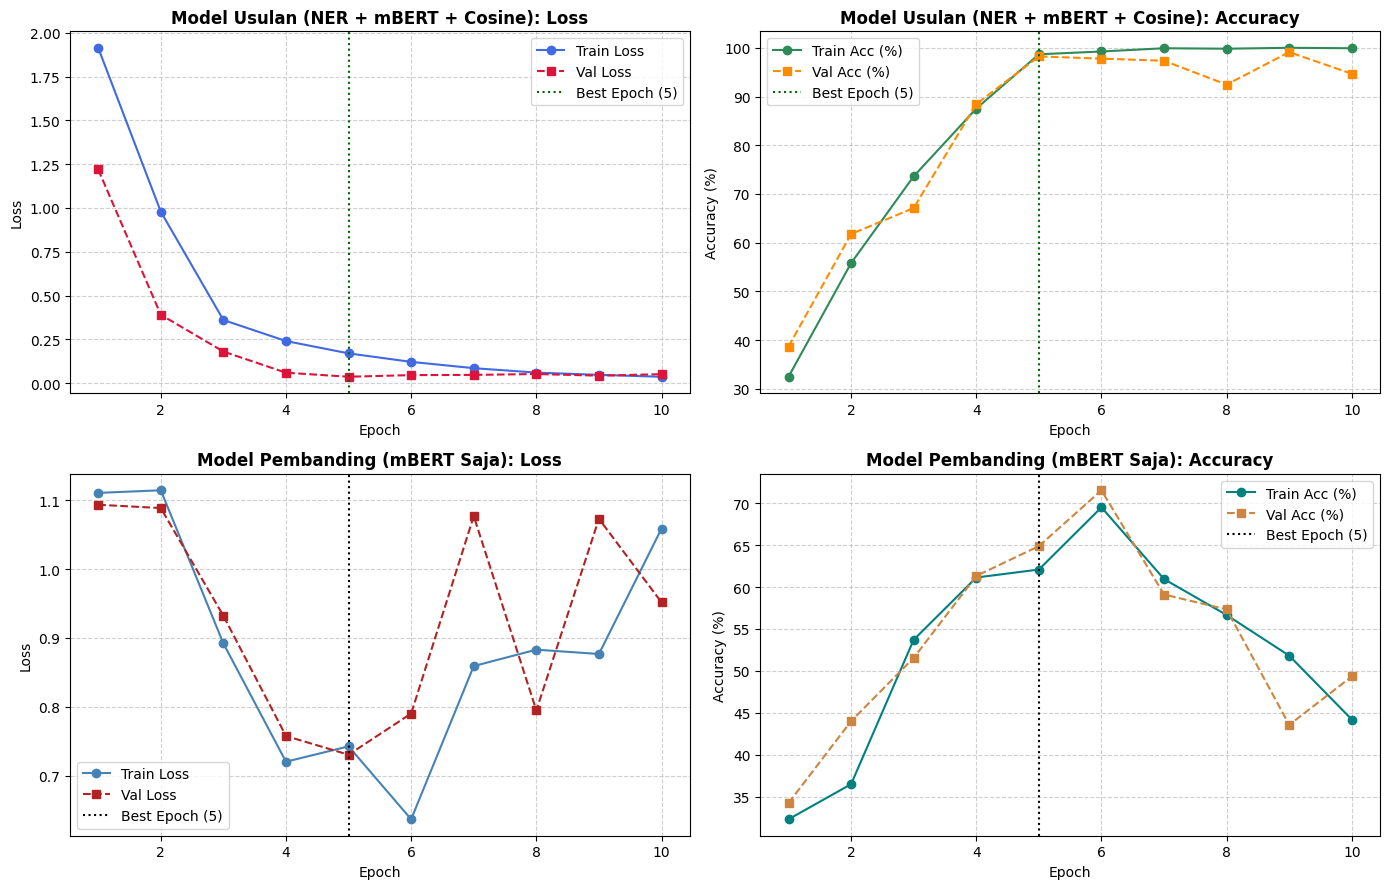

In [9]:
# 7. Grafik Train vs Val Loss & Train vs Val Accuracy
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

best_ep_m2 = history_epochs[int(np.argmin(history_val_loss))]
axes[0, 0].plot(history_epochs, history_train_loss, 'o-', color='royalblue', label='Train Loss')
axes[0, 0].plot(history_epochs, history_val_loss, 's--', color='crimson', label='Val Loss')
axes[0, 0].axvline(best_ep_m2, color='darkgreen', linestyle=':', label=f'Best Epoch ({best_ep_m2})')
axes[0, 0].set_title('Model Usulan (NER + mBERT + Cosine): Loss', fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

axes[0, 1].plot(history_epochs, history_train_acc, 'o-', color='seagreen', label='Train Acc (%)')
axes[0, 1].plot(history_epochs, history_val_acc, 's--', color='darkorange', label='Val Acc (%)')
axes[0, 1].axvline(best_ep_m2, color='darkgreen', linestyle=':', label=f'Best Epoch ({best_ep_m2})')
axes[0, 1].set_title('Model Usulan (NER + mBERT + Cosine): Accuracy', fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

best_ep_m1 = history_m1_epochs[int(np.argmin(history_m1_val_loss))]
axes[1, 0].plot(history_m1_epochs, history_m1_train_loss, 'o-', color='steelblue', label='Train Loss')
axes[1, 0].plot(history_m1_epochs, history_m1_val_loss, 's--', color='firebrick', label='Val Loss')
axes[1, 0].axvline(best_ep_m1, color='black', linestyle=':', label=f'Best Epoch ({best_ep_m1})')
axes[1, 0].set_title('Model Pembanding (mBERT Saja): Loss', fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

axes[1, 1].plot(history_m1_epochs, history_m1_train_acc, 'o-', color='teal', label='Train Acc (%)')
axes[1, 1].plot(history_m1_epochs, history_m1_val_acc, 's--', color='peru', label='Val Acc (%)')
axes[1, 1].axvline(best_ep_m1, color='black', linestyle=':', label=f'Best Epoch ({best_ep_m1})')
axes[1, 1].set_title('Model Pembanding (mBERT Saja): Accuracy', fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('learning_curves_train_val_loss_acc.png', dpi=300)
plt.show()

EVALUASI MODEL 1: mBERT SAJA (TANPA COSINE)
              precision    recall  f1-score   support

     not fit     0.7551    0.4933    0.5968        75
   close fit     0.8315    0.9867    0.9024        75
         fit     0.5977    0.6933    0.6420        75

    accuracy                         0.7244       225
   macro avg     0.7281    0.7244    0.7137       225
weighted avg     0.7281    0.7244    0.7137       225

Accuracy: 72.44% | Macro F1: 71.37% | Weighted F1: 71.37%


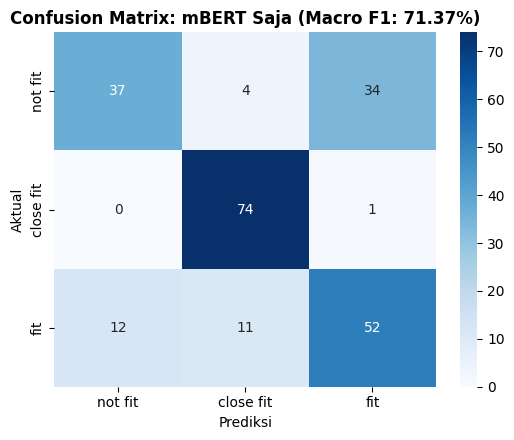

In [10]:
# 8. Evaluasi Model 1: mBERT Saja (Tanpa Cosine) pada Unseen Test Set (225 Data Uji)
test_loader_m1 = DataLoader(test_dataset_m1, batch_size=32, shuffle=False)
best_model_m1.eval()
all_test_preds_m1 = []

with torch.no_grad():
    for j_ids, j_mask, c_ids, c_mask, _ in test_loader_m1:
        j_ids, j_mask, c_ids, c_mask = j_ids.to(device), j_mask.to(device), c_ids.to(device), c_mask.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits = best_model_m1(j_ids, j_mask, c_ids, c_mask)
        all_test_preds_m1.extend(torch.argmax(logits, dim=1).cpu().numpy())

y_true_m1 = test_df['kategori'].tolist()
y_pred_m1 = [ID2LABEL[p] for p in all_test_preds_m1]

acc_m1 = accuracy_score(y_true_m1, y_pred_m1) * 100.0
macro_f1_m1 = f1_score(y_true_m1, y_pred_m1, labels=CLASS_NAMES, average='macro') * 100.0
weighted_f1_m1 = f1_score(y_true_m1, y_pred_m1, labels=CLASS_NAMES, average='weighted') * 100.0

print("EVALUASI MODEL 1: mBERT SAJA (TANPA COSINE)")
print(classification_report(y_true_m1, y_pred_m1, labels=CLASS_NAMES, target_names=CLASS_NAMES, digits=4, zero_division=0))
print(f"Accuracy: {acc_m1:.2f}% | Macro F1: {macro_f1_m1:.2f}% | Weighted F1: {weighted_f1_m1:.2f}%")

plt.figure(figsize=(5.5, 4.5))
cm_m1 = confusion_matrix(y_true_m1, y_pred_m1, labels=CLASS_NAMES)
sns.heatmap(cm_m1, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f'Confusion Matrix: mBERT Saja (Macro F1: {macro_f1_m1:.2f}%)', fontweight='bold')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.savefig('cm_model1_mbert_saja.png', dpi=300)
plt.show()

EVALUASI MODEL 2 (USULAN): NER + SIAMESE mBERT + SKLEARN COSINE
              precision    recall  f1-score   support

     not fit     1.0000    1.0000    1.0000        75
   close fit     1.0000    0.9733    0.9865        75
         fit     0.9740    1.0000    0.9868        75

    accuracy                         0.9911       225
   macro avg     0.9913    0.9911    0.9911       225
weighted avg     0.9913    0.9911    0.9911       225

Accuracy: 99.11% | Macro F1: 99.11% | Weighted F1: 99.11%


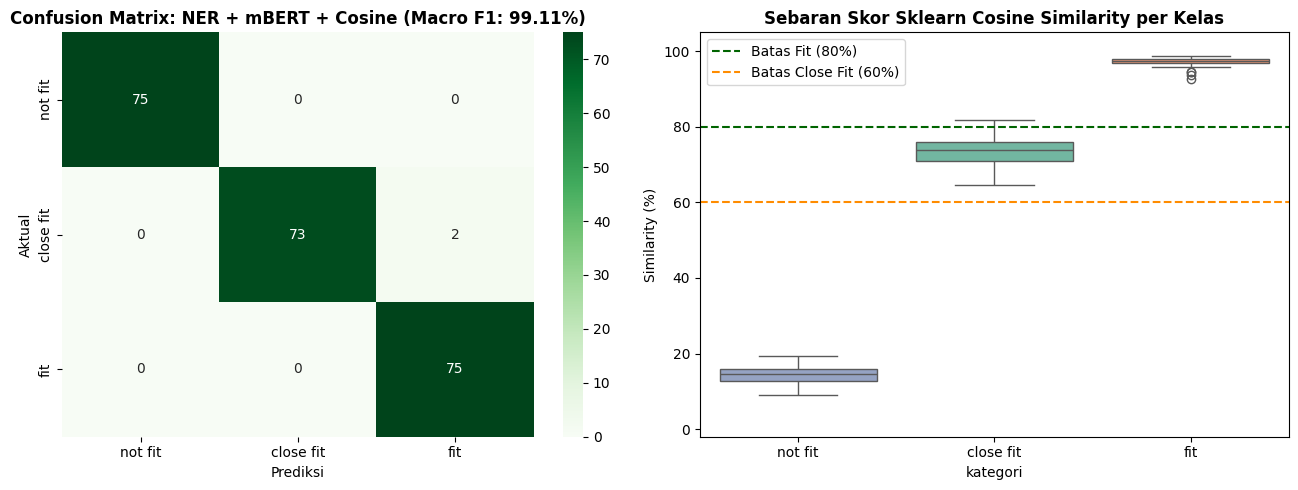

In [11]:
# 9. Evaluasi Model 2 (Usulan): Unified NER + Siamese mBERT + Sklearn Cosine Similarity (Batas Skripsi: 60% & 80%)
def extract_cls_embeddings(texts, model, tokenizer, max_length=256, batch_size=32, doc_type=None):
    model.eval()
    all_embs = []
    processed = [
        build_ner_enriched_text(str(t), doc_type=doc_type) if (not str(t).startswith('[DOC]') and doc_type) else str(t)
        for t in texts
    ]
    with torch.no_grad():
        for i in range(0, len(processed), batch_size):
            inputs = tokenizer(processed[i:i + batch_size], padding=True, truncation=True, max_length=max_length, return_tensors='pt').to(device)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                embs = model.encode_text(inputs['input_ids'], inputs['attention_mask'])
            all_embs.append(embs.cpu().numpy())
    return np.vstack(all_embs)

test_job_embs = extract_cls_embeddings(test_df['job_ner'], best_model, tokenizer, max_length=FINAL_MAX_LEN)
test_cv_embs = extract_cls_embeddings(test_df['cv_ner'], best_model, tokenizer, max_length=FINAL_MAX_LEN)
test_sims = np.clip(np.diag(cosine_similarity(test_job_embs, test_cv_embs)), 0.0, 1.0) * 100.0

# Klasifikasi menggunakan batas ambang sesuai Naskah Skripsi (Not Fit < 60%, Close Fit 60%-79.9%, Fit >= 80%)
y_true_test = test_df['kategori'].tolist()
y_pred_m2 = ['fit' if s >= 80.0 else ('close fit' if s >= 60.0 else 'not fit') for s in test_sims]

acc_m2 = accuracy_score(y_true_test, y_pred_m2) * 100.0
macro_f1_m2 = f1_score(y_true_test, y_pred_m2, labels=CLASS_NAMES, average='macro', zero_division=0) * 100.0
weighted_f1_m2 = f1_score(y_true_test, y_pred_m2, labels=CLASS_NAMES, average='weighted', zero_division=0) * 100.0

print("EVALUASI MODEL 2 (USULAN): NER + SIAMESE mBERT + SKLEARN COSINE")
print(classification_report(y_true_test, y_pred_m2, labels=CLASS_NAMES, target_names=CLASS_NAMES, digits=4, zero_division=0))
print(f"Accuracy: {acc_m2:.2f}% | Macro F1: {macro_f1_m2:.2f}% | Weighted F1: {weighted_f1_m2:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_m2 = confusion_matrix(y_true_test, y_pred_m2, labels=CLASS_NAMES)
sns.heatmap(cm_m2, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f'Confusion Matrix: NER + mBERT + Cosine (Macro F1: {macro_f1_m2:.2f}%)', fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

df_plot_m2 = test_df.copy()
df_plot_m2['Similarity (%)'] = test_sims
sns.boxplot(x='kategori', y='Similarity (%)', hue='kategori', data=df_plot_m2, order=CLASS_NAMES, palette='Set2', legend=False, ax=axes[1])
axes[1].axhline(80.0, color='darkgreen', linestyle='--', label='Batas Fit (80%)')
axes[1].axhline(60.0, color='darkorange', linestyle='--', label='Batas Close Fit (60%)')
axes[1].set_ylim(-2, 105)
axes[1].set_title('Sebaran Skor Sklearn Cosine Similarity per Kelas', fontweight='bold')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.savefig('cm_model2_mbert_plus_cosine.png', dpi=300)
plt.show()

EVALUASI MODEL 3: COSINE SAJA (TF-IDF + SKLEARN COSINE)
              precision    recall  f1-score   support

     not fit     0.3333    1.0000    0.5000        75
   close fit     0.0000    0.0000    0.0000        75
         fit     0.0000    0.0000    0.0000        75

    accuracy                         0.3333       225
   macro avg     0.1111    0.3333    0.1667       225
weighted avg     0.1111    0.3333    0.1667       225

Accuracy: 33.33% | Macro F1: 16.67% | Weighted F1: 16.67%


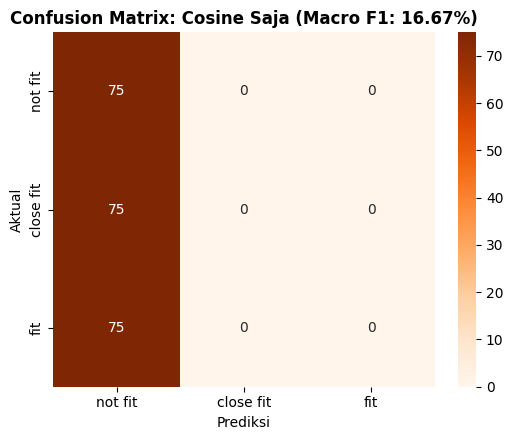

In [12]:
# 10. Evaluasi Model 3: Cosine Saja (TF-IDF + Sklearn Cosine) pada Unseen Test Set
tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))
tfidf.fit(list(train_df['job_clean']) + list(train_df['cv_clean']))

tfidf_test_sims = np.clip(np.diag(cosine_similarity(tfidf.transform(test_df['job_clean']), tfidf.transform(test_df['cv_clean']))), 0.0, 1.0) * 100.0

y_true_m3 = test_df['kategori'].tolist()
y_pred_m3 = ['fit' if s >= 80.0 else ('close fit' if s >= 60.0 else 'not fit') for s in tfidf_test_sims]

acc_m3 = accuracy_score(y_true_m3, y_pred_m3) * 100.0
macro_f1_m3 = f1_score(y_true_m3, y_pred_m3, labels=CLASS_NAMES, average='macro', zero_division=0) * 100.0
weighted_f1_m3 = f1_score(y_true_m3, y_pred_m3, labels=CLASS_NAMES, average='weighted', zero_division=0) * 100.0

print("EVALUASI MODEL 3: COSINE SAJA (TF-IDF + SKLEARN COSINE)")
print(classification_report(y_true_m3, y_pred_m3, labels=CLASS_NAMES, target_names=CLASS_NAMES, digits=4, zero_division=0))
print(f"Accuracy: {acc_m3:.2f}% | Macro F1: {macro_f1_m3:.2f}% | Weighted F1: {weighted_f1_m3:.2f}%")

plt.figure(figsize=(5.5, 4.5))
cm_m3 = confusion_matrix(y_true_m3, y_pred_m3, labels=CLASS_NAMES)
sns.heatmap(cm_m3, annot=True, fmt='d', cmap='Oranges', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f'Confusion Matrix: Cosine Saja (Macro F1: {macro_f1_m3:.2f}%)', fontweight='bold')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.savefig('cm_model3_cosine_saja.png', dpi=300)
plt.show()

REKAPITULASI KOMPARASI 3 MODEL (225 UNSEEN TEST SET):
                                          Model / Pendekatan  Accuracy (%)  Macro F1 (%)  Weighted F1 (%)
              Model 3: Cosine Saja (TF-IDF + Sklearn Cosine)         33.33         16.67            16.67
        Model 1: mBERT Saja (Tanpa Cosine - Classifier Head)         72.44         71.37            71.37
Model 2: NER + Siamese mBERT + Sklearn Cosine (Model Usulan)         99.11         99.11            99.11


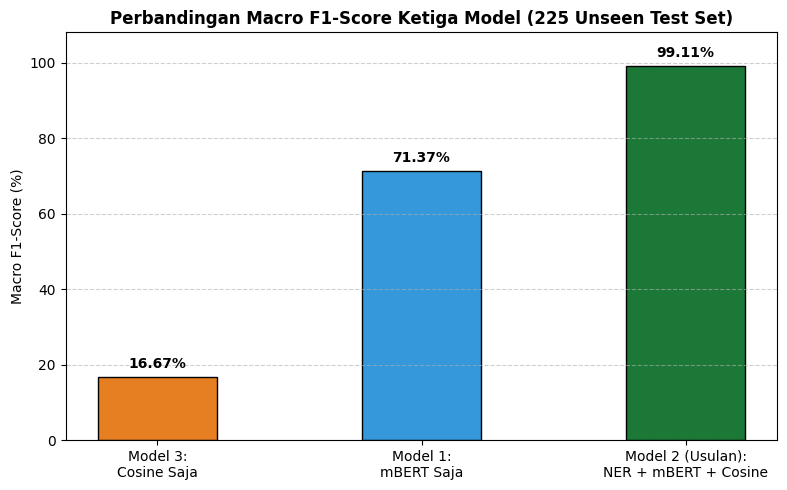

In [13]:
# 11. Tabel & Grafik Perbandingan Performa Ketiga Model pada Unseen Test Set (225 Data Uji)
df_rekapitulasi = pd.DataFrame({
    'Model / Pendekatan': [
        'Model 3: Cosine Saja (TF-IDF + Sklearn Cosine)',
        'Model 1: mBERT Saja (Tanpa Cosine - Classifier Head)',
        'Model 2: NER + Siamese mBERT + Sklearn Cosine (Model Usulan)'
    ],
    'Accuracy (%)': [round(acc_m3, 2), round(acc_m1, 2), round(acc_m2, 2)],
    'Macro F1 (%)': [round(macro_f1_m3, 2), round(macro_f1_m1, 2), round(macro_f1_m2, 2)],
    'Weighted F1 (%)': [round(weighted_f1_m3, 2), round(weighted_f1_m1, 2), round(weighted_f1_m2, 2)]
})

print("REKAPITULASI KOMPARASI 3 MODEL (225 UNSEEN TEST SET):")
print(df_rekapitulasi.to_string(index=False))

plt.figure(figsize=(8, 5))
model_names = ['Model 3:\nCosine Saja', 'Model 1:\nmBERT Saja', 'Model 2 (Usulan):\nNER + mBERT + Cosine']
f1_values = [macro_f1_m3, macro_f1_m1, macro_f1_m2]
bars = plt.bar(model_names, f1_values, color=['#e67e22', '#3498db', '#1b7837'], width=0.45, edgecolor='black')
plt.title('Perbandingan Macro F1-Score Ketiga Model (225 Unseen Test Set)', fontweight='bold')
plt.ylabel('Macro F1-Score (%)')
plt.ylim(0, 108)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 1.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('rekapitulasi_komparasi_3_model.png', dpi=300)
plt.show()

In [14]:
# 12. Simulasi Inferensi End-to-End CV vs Job Description (Tabel 2.5 & Tabel 2 Proposal)
def predict_cv_job_matching_interactive(job_text, cv_text):
    clean_j = regex_standardize_text(job_text)
    clean_c = regex_standardize_text(cv_text)

    ner_job = extract_ner_entities_mbert_hybrid(clean_j)
    ner_cv = extract_ner_entities_mbert_hybrid(clean_c)

    enriched_j = build_ner_enriched_text(clean_j, doc_type='JOB_POSTING')
    enriched_c = build_ner_enriched_text(clean_c, doc_type='CANDIDATE_CV')

    emb_j = extract_cls_embeddings([enriched_j], best_model, tokenizer, max_length=FINAL_MAX_LEN)[0]
    emb_c = extract_cls_embeddings([enriched_c], best_model, tokenizer, max_length=FINAL_MAX_LEN)[0]

    sklearn_sim = float(cosine_similarity(emb_c.reshape(1, -1), emb_j.reshape(1, -1))[0][0])
    sim_score = max(0.0, min(1.0, sklearn_sim)) * 100.0

    kategori = "Fit" if sim_score >= 80.0 else ("Close Fit" if sim_score >= 60.0 else "Not Fit")

    df_tabel2 = pd.DataFrame({
        'Entitas NER': ['[EDU] Pendidikan', '[ORG] Organisasi', '[ROLE] Jabatan', '[DUR] Pengalaman', '[SKILL] Keahlian', 'Vektor (768-d)'],
        'CV Pelamar': [
            ', '.join(ner_cv['EDU']) or '-', ', '.join(ner_cv['ORG']) or '-',
            ', '.join(ner_cv['ROLE']) or '-', ', '.join(ner_cv['DUR']) or '-',
            ', '.join(ner_cv['SKILL']) or '-', str([round(float(x), 4) for x in emb_c[:4]]) + ' ...'
        ],
        'Job Description': [
            ', '.join(ner_job['EDU']) or '-', ', '.join(ner_job['ORG']) or '-',
            ', '.join(ner_job['ROLE']) or '-', ', '.join(ner_job['DUR']) or '-',
            ', '.join(ner_job['SKILL']) or '-', str([round(float(x), 4) for x in emb_j[:4]]) + ' ...'
        ]
    })
    print(df_tabel2.to_string(index=False))
    print(f"\nSkor Cosine Similarity: {sim_score:.2f}% -> Kategori: {kategori} (Batas Skripsi: Fit >= 80%, Close Fit 60%-79.9%, Not Fit < 60%)")

sample_job = (
    "Position: Software Engineer. Experience Level: Entry level. "
    "Job Description: PT Telekomunikasi Indonesia membutuhkan Software Engineer lulusan S1 Informatika "
    "yang menguasai Python, Go, C#, SQL, dan Docker dengan pengalaman minimal 6 bulan."
)
sample_cv = (
    "Lulusan S1 Informatika dari Universitas Surabaya yang menguasai Python, Go, dan C# "
    "dan memiliki pengalaman magang sebagai Software Engineer di PT Telekomunikasi Indonesia selama 6 bulan."
)
predict_cv_job_matching_interactive(sample_job, sample_cv)

     Entitas NER                                        CV Pelamar                                 Job Description
[EDU] Pendidikan                                    S1 Informatika                                  S1 Informatika
[ORG] Organisasi Universitas Surabaya, PT Telekomunikasi Indonesia                     PT Telekomunikasi Indonesia
  [ROLE] Jabatan                                 Software Engineer                               Software Engineer
[DUR] Pengalaman                                           6 bulan                            6 bulan, Entry level
[SKILL] Keahlian                Python, Go, Software, Engineer, C# Software, Engineer, Python, Go, SQL, Docker, C#
  Vektor (768-d)            [0.0266, -0.0219, 0.0234, -0.0584] ...          [0.0241, -0.0207, 0.0341, -0.0612] ...

Skor Cosine Similarity: 96.77% -> Kategori: Fit (Batas Skripsi: Fit >= 80%, Close Fit 60%-79.9%, Not Fit < 60%)


In [15]:
# 13. Simpan & Download Bobot Model (.pt) beserta Grafik Evaluasi (.png)
import json
import zipfile

os.makedirs('./models', exist_ok=True)
model_metadata = {
    'model_name': MODEL_NAME,
    'best_params_m2_cosine': best_params_m2,
    'best_params_m1_saja': best_params_m1,
    'threshold_close_fit_pct': 60.0,
    'threshold_fit_pct': 80.0,
    'macro_f1_m2_cosine_pct': round(float(macro_f1_m2), 2),
    'macro_f1_m1_saja_pct': round(float(macro_f1_m1), 2),
    'macro_f1_m3_tfidf_pct': round(float(macro_f1_m3), 2)
}
with open('./models/model_config_metadata.json', 'w', encoding='utf-8') as f_meta:
    json.dump(model_metadata, f_meta, indent=2)

charts_zip_path = 'grafik_dan_metadata_skripsi.zip'
with zipfile.ZipFile(charts_zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write('./models/model_config_metadata.json', arcname='model_config_metadata.json')
    for fname in os.listdir('.'):
        if fname.endswith('.png'):
            zf.write(fname, arcname=fname)

print(f"File model & paket grafik siap: ./models/best_siamese_mbert_cosine.pt, {charts_zip_path}")
try:
    from google.colab import files
    files.download(charts_zip_path)
    files.download('./models/best_siamese_mbert_cosine.pt')
except ImportError:
    pass

File model & paket grafik siap: ./models/best_siamese_mbert_cosine.pt, grafik_dan_metadata_skripsi.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>